In [ ]:
import seaborn

from astropy import units

from selflensing.models import LensingEvent
from selflensing.fitting import self_lensing_system_from_rv_fit

from realistic import load_realistic_timeseries
from utils import DEFAULTS, default_times

In [32]:
rts = load_realistic_timeseries()

In [33]:
peak_time = default_times[0]

In [34]:
idx = 20000
ts = rts.iloc[idx]

In [35]:
ts

index                                                           2500
a                                                           1.188889
e                                                                0.4
periapsis_phase                                             5.585054
Macc                                                             0.1
Porb                                                        451.4545
Mcomp                                                            1.0
Rcomp                                                            1.0
b                                                                0.0
rv                 [-470.3510797884965, 1008.9290509386162, 3916....
rv_err                                                     500.09999
times              [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...
RV accuracy                                                    500.0
cadence                                                            1
pristine idx                      

<Axes: xlabel='times', ylabel='rv'>

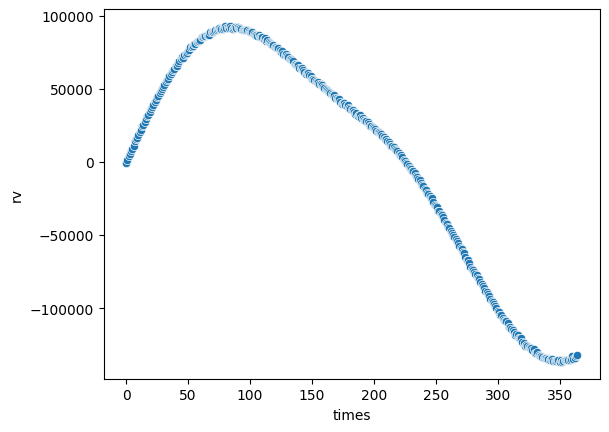

In [36]:
seaborn.scatterplot(ts.to_dict(), x='times', y='rv')

In [ ]:
sls, sampler = self_lensing_system_from_rv_fit(
    ts['rv'] * units.m / units.s,
    ts['rv_err'] * units.m / units.s,
    DEFAULTS['start_time'] + ts['times'] * units.day,
    Mcomp=DEFAULTS['Mcomp'],
    Rcomp=DEFAULTS['Rcomp'],
    peak_time=DEFAULTS['start_time'],
    Teff=DEFAULTS['Teff'],
)

  0%|          | 0/5000 [00:00<?, ?it/s]/Users/adam/.local/share/virtualenvs/src-VJqicAka/lib/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [02:02<00:00, 40.92it/s]


In [38]:
import numpy
numpy.median(sampler.get_chain(flat=True, discard=100), axis=0)

array([ 3.89762512, 37.53474158,  0.39915274,  5.58243258])

In [39]:
# sls.a = 1 * units.AU
le = LensingEvent(sls, DEFAULTS['start_time'])

In [40]:
sls.a, sls.Macc, sls.e, sls.periapsis_phase, sls.porb

(<Quantity 3.89423374 AU>,
 <Quantity 37.65390924 solMass>,
 <Quantity 0.39909815>,
 <Quantity 5.58374078 rad>,
 <Quantity 451.47607305 d>)

<Axes: xlabel='times', ylabel='rv'>

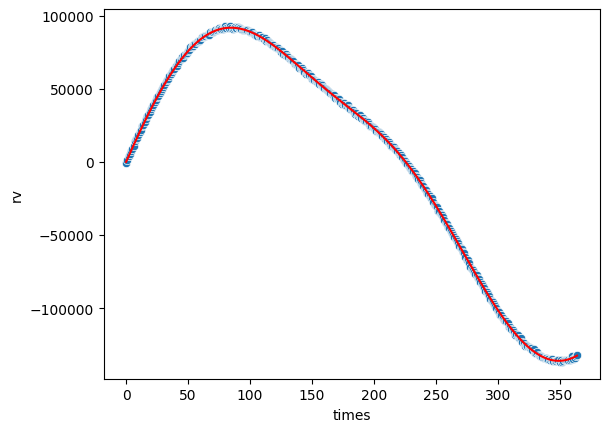

In [41]:
seaborn.scatterplot(ts.to_dict(), x='times', y='rv')
seaborn.lineplot({'times': default_times, 'rv': le.rv_range(DEFAULTS['start_time'], DEFAULTS['end_time'])}, x='times', y='rv', color='red')

Text(0.5, 0, 'step number')

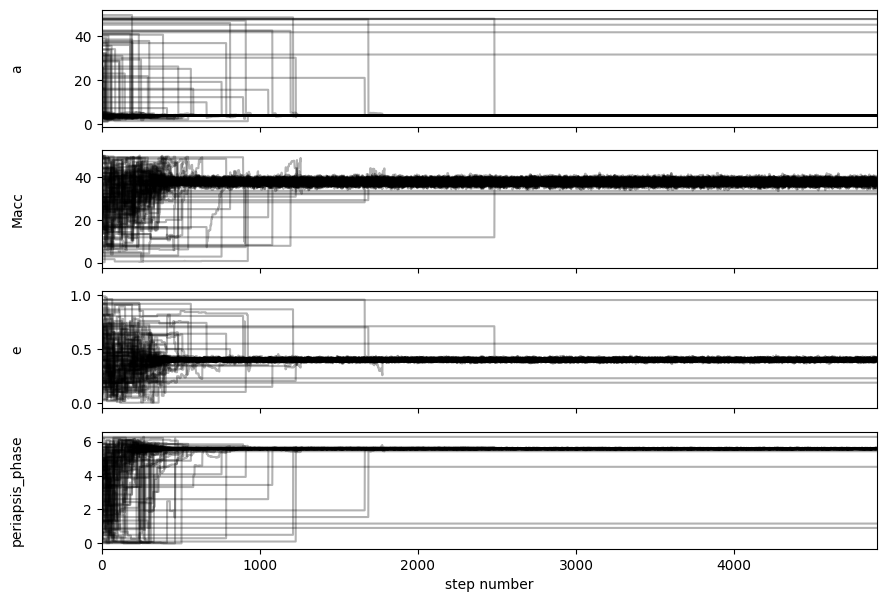

In [42]:
from matplotlib import pyplot as plt
labels = ["a", "Macc", 'e', 'periapsis_phase']
fig, axes = plt.subplots(len(labels), figsize=(10, 7), sharex=True)
samples = sampler.get_chain(discard=100)
flat_samples = sampler.get_chain(flat=True)
for i in range(len(labels)):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")

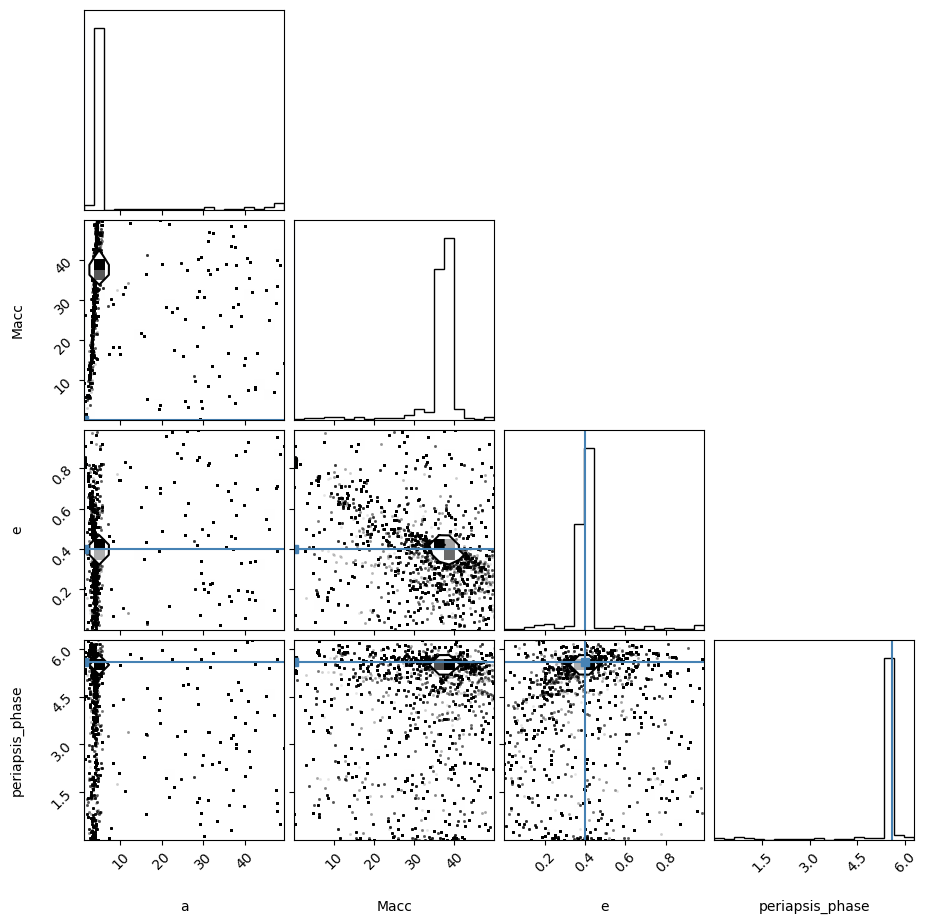

In [43]:
import corner

fig = corner.corner(
    flat_samples, labels=labels, truths=[ts['a'], ts['Macc'], ts['e'], ts['periapsis_phase']]
)